# 04 — Train và đánh giá IDS cửa sổ (benign / recon / bruteforce)

Theo `PLAN_tron_nen_window.md` mục 4 (bước 04).

- Hai model: `hgb` (HistGradientBoosting — tham chiếu độ chính xác) và `dtree` (cây quyết định giới hạn độ sâu — dễ xuất sang C cho OpenWrt).
- Ngưỡng báo động chọn trên **val**: `score = 1 − P(benign)`, lấy ngưỡng thấp nhất sao cho báo động sai ≤ `TARGET_FP_PER_HOUR` trên cửa sổ nền của các ngày val.
- Đánh giá trên **test**: báo động sai/giờ (ngày nền test), tỷ lệ phát hiện **theo task** và độ trễ, phân lớp recon/bruteforce, báo động trên cửa sổ benign của chính máy tấn công (persona) và máy đích.
- `arp_discovery` (2 task, đều ở train): leave-one-task-out.
- Lưu theo thời gian: `Model/<model>/<YYYYMMDD_HHMM>/` + `Model/<model>/runs.csv`.

In [1]:
import json, time
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

ROOT = Path('/home/ubuntu/sepcung/03.Brute_Force_vs_Recon')
WIN_DIR = ROOT / 'Data_after_processing' / 'windows'
MODEL_ROOT = ROOT / 'Model'
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M')
RUN_NOTE = 'v2: trọng số kịch bản ∝ sqrt(số cửa sổ) + trần 0,1%/cửa sổ; hgb tắt early stopping nội bộ, chọn số vòng theo val loss'

HOP = 10
TARGET_FP_PER_HOUR = 1.0
CLASSES = ['benign', 'recon', 'bruteforce']
ATTACKER_IP, TARGET_IP = '192.168.1.236', '192.168.1.182'
MODELS = {
    # early_stopping nội bộ của sklearn tách ngẫu nhiên 10% dòng (cùng task ở cả 2 phía) -> tắt, chọn số vòng theo val
    'hgb': lambda **kw: HistGradientBoostingClassifier(**{'max_iter': 300, 'learning_rate': 0.1, 'max_leaf_nodes': 31,
                                                          'l2_regularization': 1.0, 'early_stopping': False,
                                                          'random_state': 42, **kw}),
    'dtree': lambda: DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=42),
}

data = {s: pd.read_csv(WIN_DIR / f'{s}.csv', low_memory=False) for s in ['train', 'val', 'test']}
FEATURES = [c for c in data['train'].columns if c.startswith('f_')]
hours = {s: d.loc[d['source'] == 'benign_day'].groupby('day')['b'].agg(lambda b: (b.max() - b.min() + 1) * HOP / 3600).sum()
         for s, d in data.items()}
pd.DataFrame({s: {'rows': len(d), 'use_train': int(d['use_train'].sum()), 'benign_hours': round(hours[s], 1)}
              for s, d in data.items()})

,train,val,test
rows,966850.0,320662.0,342700.0
use_train,936838.0,314441.0,331614.0
benign_hours,278.5,96.0,95.0


In [2]:
pd.concat({s: d.groupby(['source', 'label']).size() for s, d in data.items()}, axis=1).fillna(0).astype(int)

train     val    test
source     label                              
benign_day benign       906247  307994  319804
mix        benign        20201    4599    9256
           bruteforce     6300    1280    1383
           post_attack    3028     574    1937
           recon          4090     568    1171
           victim        26984    5647    9149

## 1. Train

In [3]:
tr = data['train'][data['train']['use_train'] == 1]
y_tr = tr['label'].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
fitted = {}
for name, make in MODELS.items():
    t0 = time.time()
    m = make()
    m.fit(tr[FEATURES].to_numpy(np.float32), y_tr, sample_weight=tr['sample_weight'].to_numpy())
    fitted[name] = m
    print(name, f'{time.time() - t0:.1f}s')

# Lịch sử hgb theo vòng boosting trên train/val (có và không trọng số) -> chọn số vòng theo val loss có trọng số
from sklearn.metrics import accuracy_score, log_loss
va = data['val'][data['val']['use_train'] == 1]
y_va = va['label'].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
hist = {'iteration': np.arange(1, fitted['hgb'].n_iter_ + 1)}
for split_name, (df, y) in {'train': (tr, y_tr), 'validation': (va, y_va)}.items():
    w = df['sample_weight'].to_numpy()
    cols = {k: [] for k in ['accuracy', 'loss', 'accuracy_unweighted', 'loss_unweighted']}
    for p in fitted['hgb'].staged_predict_proba(df[FEATURES].to_numpy(np.float32)):
        pred = p.argmax(axis=1)
        cols['accuracy'].append(accuracy_score(y, pred, sample_weight=w))
        cols['loss'].append(log_loss(y, p, sample_weight=w, labels=[0, 1, 2]))
        cols['accuracy_unweighted'].append(accuracy_score(y, pred))
        cols['loss_unweighted'].append(log_loss(y, p, labels=[0, 1, 2]))
    for k, v in cols.items():
        hist[f'{split_name}_{k}'] = v
hist = pd.DataFrame(hist)
BEST_ITER = int(hist.loc[hist['validation_loss'].idxmin(), 'iteration'])
print('vòng tốt nhất theo val loss:', BEST_ITER, '/', fitted['hgb'].n_iter_)
if BEST_ITER < fitted['hgb'].n_iter_:  # HGB không lấy mẫu ngẫu nhiên -> train lại với max_iter=BEST_ITER cho đúng các cây đầu
    fitted['hgb'] = MODELS['hgb'](max_iter=BEST_ITER).fit(tr[FEATURES].to_numpy(np.float32), y_tr,
                                                          sample_weight=tr['sample_weight'].to_numpy())

hgb 22.7s


dtree 13.6s


vòng tốt nhất theo val loss: 32 / 300


## 2. Ngưỡng trên val theo báo động sai/giờ

In [4]:
def score(m, df):
    p = m.predict_proba(df[FEATURES].to_numpy(np.float32))
    return 1 - p[:, 0], np.array(CLASSES[1:])[p[:, 1:].argmax(axis=1)]


def pick_threshold(scores_benign, hrs, target):
    k = int(np.floor(target * hrs))  # số báo động sai cho phép
    s = np.sort(scores_benign)[::-1]
    return float(np.nextafter(s[k], 1)) if k < len(s) else 0.0


thr = {}
for name, m in fitted.items():
    v = data['val']
    sc, _ = score(m, v[v['source'] == 'benign_day'])
    thr[name] = pick_threshold(sc, hours['val'], TARGET_FP_PER_HOUR)
thr

{'hgb': 0.616631198297443, 'dtree': 0.9985062905100943}

## 3. Đánh giá trên test

In [5]:
def evaluate(name, m, df, split, hrs):
    sc, cls = score(m, df)
    d = df[['source', 'sample_id', 'scenario', 'incomplete_capture', 'host', 'b', 'label', 'use_train']].copy()
    d['score'], d['alarm'] = sc, sc >= thr[name]
    d['pred'] = np.where(d['alarm'], cls, 'benign')
    res = {}
    bd = d[d['source'] == 'benign_day']
    res['fp_per_hour'] = bd['alarm'].sum() / hrs
    res['fp_hosts'] = bd[bd['alarm']].groupby('host').size().sort_values(ascending=False).head(10).to_dict()
    mixb = d[(d['source'] == 'mix') & (d['label'] == 'benign')]
    res['persona_benign_alarm_rate'] = mixb.loc[mixb['host'] == ATTACKER_IP, 'alarm'].mean()
    res['target_benign_alarm_rate'] = mixb.loc[mixb['host'] == TARGET_IP, 'alarm'].mean()
    res['victim_alarm_rate'] = d.loc[d['label'] == 'victim', 'alarm'].mean()

    att = d[d['label'].isin(['recon', 'bruteforce'])]
    per_task = att.groupby('sample_id').apply(lambda g: pd.Series({
        'scenario': g['scenario'].iat[0], 'class': g['label'].iat[0], 'incomplete_capture': g['incomplete_capture'].iat[0],
        'attack_windows': len(g), 'alarm_windows': int(g['alarm'].sum()),
        'detected': bool(g['alarm'].any()),
        'delay_s': ((g.loc[g['alarm'], 'b'].min() - g['b'].min()) * HOP) if g['alarm'].any() else np.nan,
        'class_correct': (g.loc[g['alarm'], 'pred'].mode().iat[0] == g['label'].iat[0]) if g['alarm'].any() else False,
    }), include_groups=False).reset_index()
    per_scen = per_task.groupby(['incomplete_capture', 'scenario']).agg(
        tasks=('sample_id', 'size'), detect_rate=('detected', 'mean'), class_acc=('class_correct', 'mean'),
        window_recall=('alarm_windows', lambda s: s.sum() / per_task.loc[s.index, 'attack_windows'].sum()),
        median_delay_s=('delay_s', 'median')).reset_index()
    u = d[d['use_train'] == 1]
    res['report'] = classification_report(u['label'], u['pred'], labels=CLASSES, output_dict=True, zero_division=0)
    res['cm'] = pd.DataFrame(confusion_matrix(u['label'], u['pred'], labels=CLASSES),
                             index=[f'true_{c}' for c in CLASSES], columns=[f'pred_{c}' for c in CLASSES])
    return res, per_task, per_scen


results = {}
for name, m in fitted.items():
    results[name] = evaluate(name, m, data['test'], 'test', hours['test'])
    r = results[name][0]
    print(f"== {name}: thr={thr[name]:.4f}  FP/giờ={r['fp_per_hour']:.2f}  "
          f"persona benign alarm={r['persona_benign_alarm_rate']:.3f}  camera benign alarm={r['target_benign_alarm_rate']:.3f}  "
          f"victim alarm={r['victim_alarm_rate']:.3f}")
    print('   host báo sai nhiều nhất:', r['fp_hosts'])
    display(r['cm'])
    display(results[name][2].round(3))

== hgb: thr=0.6166  FP/giờ=3.29  persona benign alarm=0.019  camera benign alarm=0.000  victim alarm=0.107
   host báo sai nhiều nhất: {'192.168.1.239': 143, '192.168.1.208': 130, '192.168.1.3': 29, '192.168.1.163': 4, '192.168.1.248': 4, '192.168.1.112': 1, '192.168.1.243': 1, '192.168.1.241': 1}


,pred_benign,pred_recon,pred_bruteforce
true_benign,328707,135,218
true_recon,299,869,3
true_bruteforce,7,0,1376


,incomplete_capture,scenario,tasks,detect_rate,class_acc,window_recall,median_delay_s
0,0.0,firewall_ack_mapping,38,0.974,0.947,0.948,0.0
1,0.0,ssh,44,1.000,1.000,0.995,0.0
2,0.0,stealth_fin_scan,2,1.000,1.000,1.000,0.0
3,0.0,stealth_null_scan,2,1.000,1.000,1.000,0.0
4,0.0,stealth_xmas_scan,2,1.000,1.000,1.000,0.0
5,0.0,tcp_connect_scan,4,1.000,1.000,1.000,0.0
6,0.0,tcp_syn_scan,60,1.000,1.000,0.998,0.0
7,0.0,udp_port_scan,16,0.875,0.875,0.900,0.0
8,1.0,icmp_echo_discovery,118,0.059,0.059,0.040,0.0
9,1.0,tcp_ack_host_discovery,22,0.864,0.818,0.833,0.0


== dtree: thr=0.9985  FP/giờ=0.58  persona benign alarm=0.003  camera benign alarm=0.000  victim alarm=0.009
   host báo sai nhiều nhất: {'192.168.1.208': 38, '192.168.1.239': 14, '192.168.1.3': 2, '192.168.1.112': 1}


,pred_benign,pred_recon,pred_bruteforce
true_benign,328999,61,0
true_recon,353,818,0
true_bruteforce,1381,0,2


,incomplete_capture,scenario,tasks,detect_rate,class_acc,window_recall,median_delay_s
0,0.0,firewall_ack_mapping,38,0.974,0.974,0.906,0.0
1,0.0,ssh,44,0.023,0.023,0.001,330.0
2,0.0,stealth_fin_scan,2,1.000,1.000,1.000,0.0
3,0.0,stealth_null_scan,2,1.000,1.000,1.000,0.0
4,0.0,stealth_xmas_scan,2,1.000,1.000,1.000,0.0
5,0.0,tcp_connect_scan,4,1.000,1.000,0.800,0.0
6,0.0,tcp_syn_scan,60,1.000,1.000,0.989,0.0
7,0.0,udp_port_scan,16,0.500,0.500,0.600,0.0
8,1.0,icmp_echo_discovery,118,0.000,0.000,0.000,NaN
9,1.0,tcp_ack_host_discovery,22,0.727,0.727,0.600,0.0


## 4. `arp_discovery`: leave-one-task-out (model `hgb`)

In [6]:
loto = []
arp_ids = data['train'].loc[data['train']['scenario'] == 'arp_discovery', 'sample_id'].unique()
for sid in arp_ids:
    trn = tr[tr['sample_id'] != sid]
    m = MODELS['hgb'](max_iter=BEST_ITER)
    m.fit(trn[FEATURES].to_numpy(np.float32), trn['label'].map({c: i for i, c in enumerate(CLASSES)}).to_numpy(),
          sample_weight=trn['sample_weight'].to_numpy())
    held = data['train'][(data['train']['sample_id'] == sid) & (data['train']['label'] == 'recon')]
    sc, cls = score(m, held)
    loto.append({'sample_id': sid, 'attack_windows': len(held), 'alarm_windows': int((sc >= thr['hgb']).sum()),
                 'max_score': float(sc.max()), 'pred_class': pd.Series(cls[sc >= thr['hgb']]).mode().tolist()})
loto = pd.DataFrame(loto)
loto

,sample_id,attack_windows,alarm_windows,max_score,pred_class
0,arp_discovery_0001,1,0,0.058039,[]
1,arp_discovery_0002,2,0,0.114471,[]


## 5. Lưu model và báo cáo theo thời gian

In [7]:
for name, m in fitted.items():
    run_dir = MODEL_ROOT / name / RUN_ID
    run_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump({'model': m, 'features': FEATURES, 'classes': CLASSES, 'threshold': thr[name], 'hop': HOP}, run_dir / 'model.joblib')
    r, per_task, per_scen = results[name]
    per_task.to_csv(run_dir / 'test_per_task.csv', index=False)
    per_scen.to_csv(run_dir / 'test_per_scenario.csv', index=False)
    r['cm'].to_csv(run_dir / 'test_confusion_matrix.csv')
    pd.DataFrame(r['report']).T.to_csv(run_dir / 'test_classification_report.csv')
    if name == 'hgb':
        loto.to_csv(run_dir / 'arp_discovery_loto.csv', index=False)
    if name == 'dtree':
        pd.Series(m.feature_importances_, index=FEATURES).sort_values(ascending=False).to_csv(run_dir / 'feature_importance.csv')
    cfg = {'run_id': RUN_ID, 'note': RUN_NOTE, 'model': name, 'params': m.get_params(),
           'best_iter': BEST_ITER if name == 'hgb' else None, 'threshold': thr[name],
           'target_fp_per_hour': TARGET_FP_PER_HOUR, 'n_features': len(FEATURES), 'hop': HOP,
           'inputs': {s: {'path': str(WIN_DIR / f'{s}.csv'),
                          'mtime': datetime.fromtimestamp((WIN_DIR / f'{s}.csv').stat().st_mtime).isoformat()}
                      for s in ['train', 'val', 'test']}}
    (run_dir / 'run_config.json').write_text(json.dumps(cfg, ensure_ascii=False, indent=2, default=str))
    comp = per_scen[per_scen['incomplete_capture'] == 0]
    row = {'run_id': RUN_ID, 'note': RUN_NOTE, 'threshold': thr[name], 'fp_per_hour_test': r['fp_per_hour'],
           'task_detect_rate_test': float((comp['detect_rate'] * comp['tasks']).sum() / comp['tasks'].sum()),
           'macro_f1_test': r['report']['macro avg']['f1-score'],
           'persona_benign_alarm_rate': r['persona_benign_alarm_rate']}
    runs = MODEL_ROOT / name / 'runs.csv'
    pd.DataFrame([row]).to_csv(runs, mode='a', header=not runs.exists(), index=False)
    print(name, '->', run_dir)

hgb -> /home/ubuntu/sepcung/03.Brute_Force_vs_Recon/Model/hgb/20261102_1116
dtree -> /home/ubuntu/sepcung/03.Brute_Force_vs_Recon/Model/dtree/20261102_1116


## 6. Hình: confusion matrix và train history

- **Confusion matrix** trên test, dự đoán theo ngưỡng đã chọn trên val; ô ghi tỷ lệ theo hàng và (số cửa sổ).
  Bỏ 3 kịch bản host discovery thiếu ARP (`incomplete_capture=1`) — kết quả của chúng đã có ở bảng theo kịch bản.
  Xuất cả bản 2 lớp (Benign/Attack) và 3 lớp.
- **Train history** của `hgb`: gradient boosting không có epoch, nên vẽ accuracy và loss theo từng vòng boosting
  (`staged_predict_proba`) trên đủ 300 vòng; đường đứt là vòng được chọn theo val loss.
  Hình chính tính có `sample_weight` (đúng mục tiêu tối ưu); hình phụ không trọng số để thấy khi vài mẫu nặng chi phối.
- Hình lưu vào thư mục run của từng model.

== hgb (ngưỡng 0.6166, 326,629 cửa sổ test)


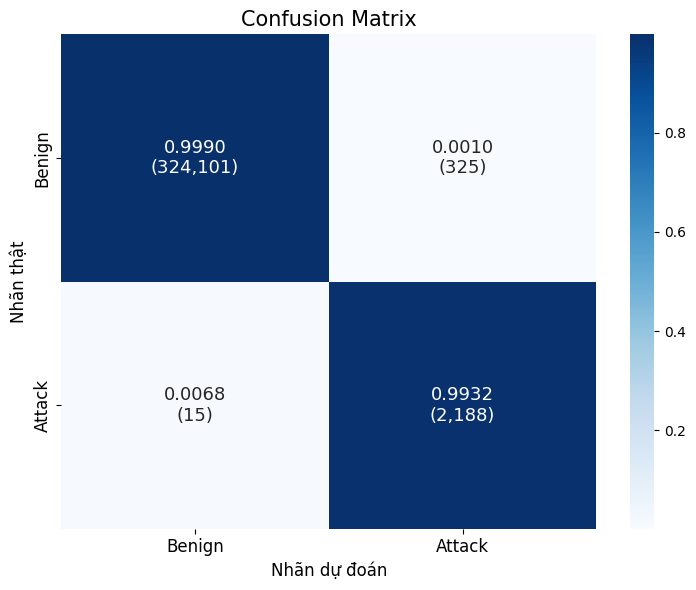

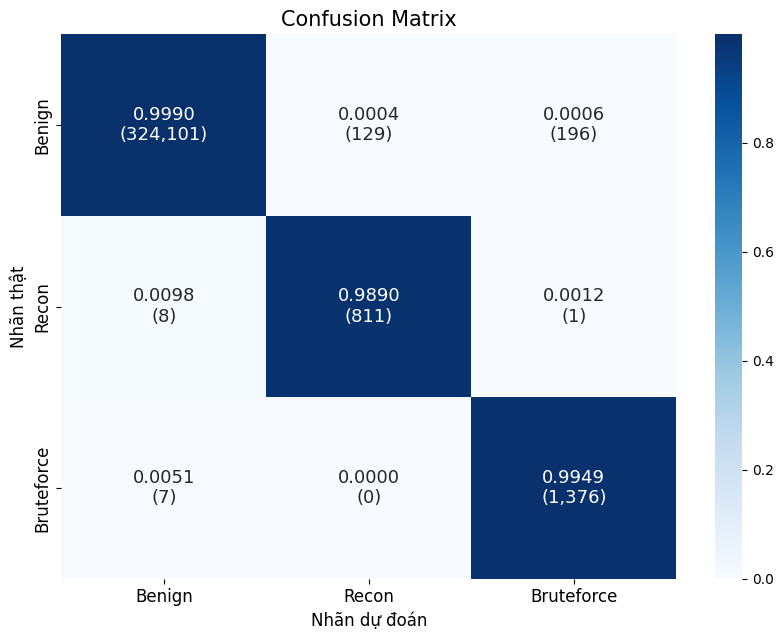

== dtree (ngưỡng 0.9985, 326,629 cửa sổ test)


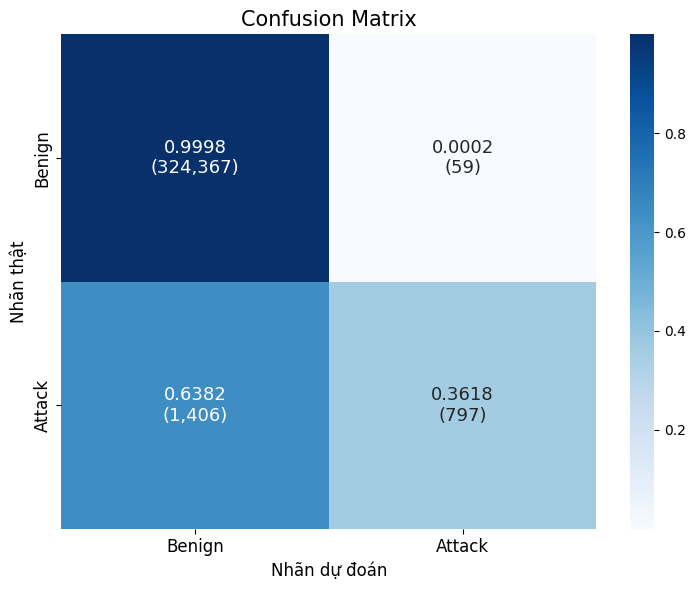

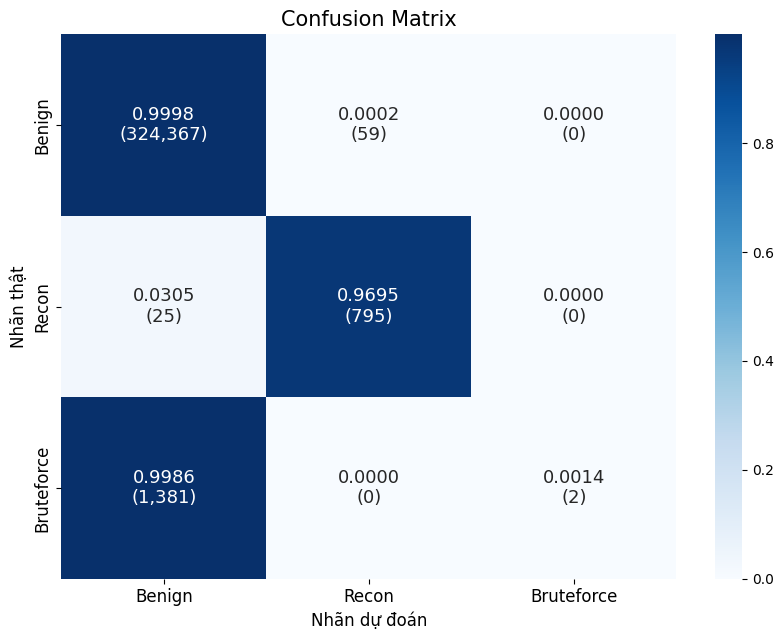

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_cm(y_true, y_pred, labels, names, path):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f'{norm[i, j]:.4f}\n({cm[i, j]:,})' for j in range(len(labels))] for i in range(len(labels))])
    fig, ax = plt.subplots(figsize=(7.5, 6) if len(labels) == 2 else (8.5, 6.5))
    sns.heatmap(norm, annot=annot, fmt='', cmap='Blues', xticklabels=names, yticklabels=names,
                annot_kws={'fontsize': 13}, ax=ax)
    ax.set_title('Confusion Matrix', fontsize=15)
    ax.set_xlabel('Nhãn dự đoán', fontsize=12)
    ax.set_ylabel('Nhãn thật', fontsize=12)
    ax.tick_params(labelsize=12)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    return pd.DataFrame(cm, index=names, columns=names)


te = data['test']
te = te[(te['use_train'] == 1) & (te['incomplete_capture'] == 0)]
for name, m in fitted.items():
    run_dir = MODEL_ROOT / name / RUN_ID
    sc, cls = score(m, te)
    pred3 = np.where(sc >= thr[name], cls, 'benign')
    print(f'== {name} (ngưỡng {thr[name]:.4f}, {len(te):,} cửa sổ test)')
    cm2 = plot_cm(np.where(te['label'] == 'benign', 'Benign', 'Attack'), np.where(pred3 == 'benign', 'Benign', 'Attack'),
                  ['Benign', 'Attack'], ['Benign', 'Attack'], run_dir / 'confusion_matrix_binary.png')
    cm3 = plot_cm(te['label'], pred3, CLASSES, ['Benign', 'Recon', 'Bruteforce'], run_dir / 'confusion_matrix_3class.png')
    cm2.to_csv(run_dir / 'test_confusion_matrix_binary.csv')
    cm3.to_csv(run_dir / 'test_confusion_matrix_3class.csv')

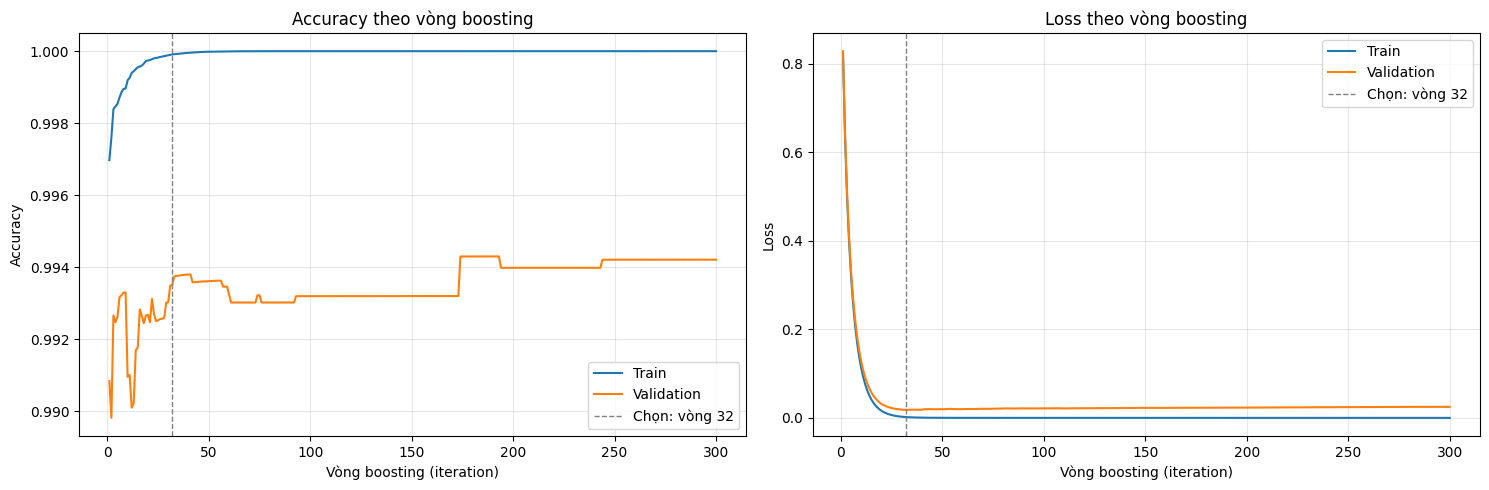

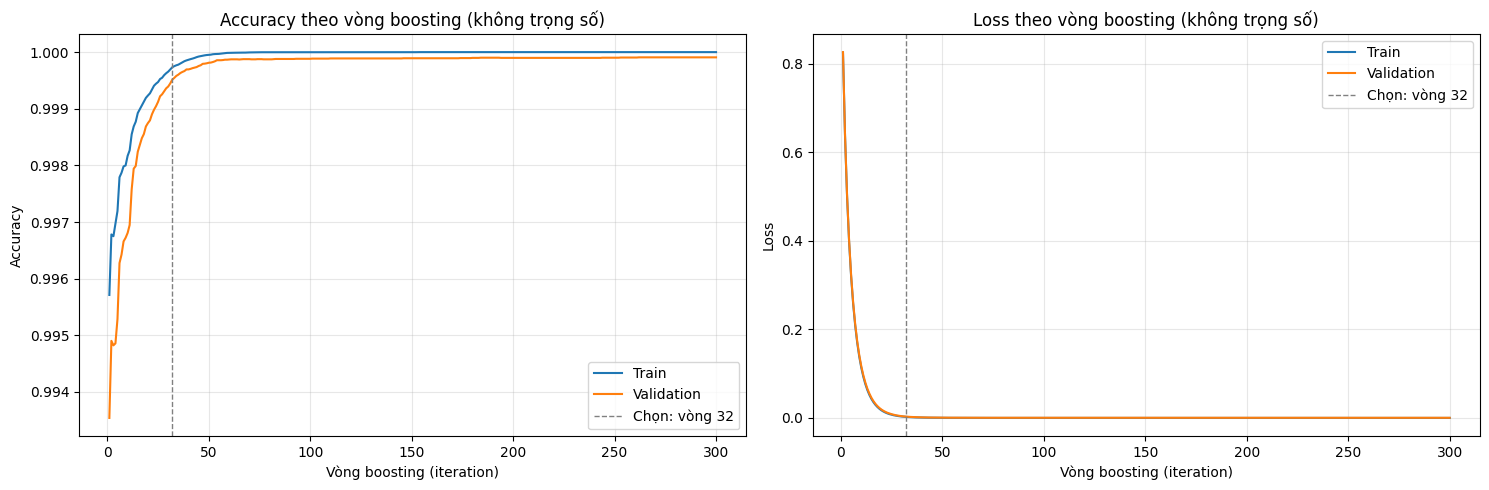

,iteration,train_accuracy,train_loss,train_accuracy_unweighted,train_loss_unweighted,validation_accuracy,validation_loss,validation_accuracy_unweighted,validation_loss_unweighted
0,1,0.9970,0.8244,0.9957,0.8252,0.9908,0.8289,0.9935,0.8264
9,10,0.9992,0.1119,0.9982,0.1138,0.9910,0.1272,0.9968,0.1173
31,32,0.9999,0.0019,0.9997,0.0023,0.9935,0.0182,0.9995,0.0030
49,50,1.0000,0.0002,1.0000,0.0002,0.9936,0.0197,0.9998,0.0006
299,300,1.0000,0.0000,1.0000,0.0000,0.9942,0.0250,0.9999,0.0003


In [ ]:
# Train history của hgb theo vòng boosting (đã tính ở mục 1)
run_dir = MODEL_ROOT / 'hgb' / RUN_ID
hist.to_csv(run_dir / 'train_history.csv', index=False)


def plot_history(suffix, path, note):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, metric, title in [(axes[0], 'accuracy', 'Accuracy'), (axes[1], 'loss', 'Loss')]:
        ax.plot(hist['iteration'], hist[f'train_{metric}{suffix}'], label='Train')
        ax.plot(hist['iteration'], hist[f'validation_{metric}{suffix}'], label='Validation')
        ax.axvline(BEST_ITER, color='gray', linestyle='--', linewidth=1, label=f'Chọn: vòng {BEST_ITER}')
        ax.set_title(f'{title}{note}')
        ax.set_xlabel('Vòng boosting (iteration)')
        ax.set_ylabel('Accuracy' if metric == 'accuracy' else 'Loss')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


plot_history('', run_dir / 'train_history.png', '')
plot_history('_unweighted', run_dir / 'train_history_unweighted.png', ' (không trọng số)')
hist.iloc[sorted({0, 9, 49, BEST_ITER - 1, len(hist) - 1})].round(4)

In [10]:
# Đặc trưng quan trọng nhất của cây quyết định (model hướng tới router)
pd.Series(fitted['dtree'].feature_importances_, index=FEATURES).sort_values(ascending=False).head(15).round(3)

f_ack_only_10         0.405
f_rx_rst_300          0.379
f_port_per_dst_10     0.128
f_rx_synack_60        0.018
f_d_icmp_300          0.013
f_synack_10           0.011
f_bytes_per_pkt_10    0.009
f_rx_rst_10           0.008
f_pkts_10             0.004
f_arp_req_60          0.004
f_d_dst_300           0.002
f_syn_ratio_10        0.002
f_rx_rst_ratio_10     0.002
f_ack_only_60         0.002
f_syn_ratio_60        0.001
dtype: float64